In [ ]:
# https://www.kaggle.com/datasets/satyampd/consumer-price-index-india-inflation-data

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


# numpy as np: Provides numerical operations, used here for generating simulated data (e.g., random values for General index).
# pandas as pd: Enables data manipulation, such as loading CSV files, filtering rows, and calculating CPI_Inflation.
# tensorflow as tf: Framework for building and training the neural network (used later in the lab, not in this segment).
# sklearn.preprocessing.StandardScaler: Standardizes features to have mean=0 and standard deviation=1, improving neural network performance (used later).
# sklearn.model_selection.train_test_split: Splits data into training and testing sets (used later).
# matplotlib.pyplot as plt: Creates plots for visualizing results (used later for loss and prediction plots).

# Step 1: Load and explore the Kaggle dataset
# Replace 'indian_cpi.csv' with the actual Kaggle dataset file name
try:
    df = pd.read_csv('/content/All_India_Index_july2019_20Aug2020.csv')  # Update with correct file path
except FileNotFoundError:
    print("Dataset not found. Please download from Kaggle (e.g., search 'Indian CPI Inflation').")
    # Simulate a dataset for demonstration
    data = {
        'Year': [2013 + i//12 for i in range(96)],
        'Month': pd.date_range(start='2013-01-01', end='2020-12-01', freq='M'),
        'Sector': ['Rural+Urban'] * 96,
        'General index': np.random.normal(loc=128, scale=12, size=96),
        'Fuel and light': np.random.normal(loc=125, scale=12, size=96),
        'Food and beverages': np.random.normal(loc=130, scale=12, size=96)
    }
    df = pd.DataFrame(data)

# Fix datetime: Create 'Month' from 'Year' assuming monthly data
# Assume each year has 12 entries (Jan to Dec)
df['Year'] = df['Year'].fillna(df['Year'].mean()).astype(int)  # Fill missing Years
df['Month'] = pd.to_datetime(df['Year'].astype(str) + '-' + ((df.index % 12) + 1).astype(str) + '-01', format='%Y-%m-%d')


# try Block:
# Attempts to load the CSV file located at /content/All_India_Index_july2019_20Aug2020.csv using pd.read_csv.
# The file path suggests a specific dataset (likely downloaded from Kaggle), covering All India CPI indices from July 2019 to August 2020, but the code assumes it contains data from 2013–2020 with columns like Year, Sector, General index, Fuel and light, and Food and beverages.
# except FileNotFoundError:
# If the CSV file is not found, prints a message instructing the user to download a dataset from Kaggle (e.g., search for “Indian CPI Inflation” or a dataset like “Indian Economy” by viveksharmar).
# Simulated Dataset:
# Creates a fallback dataset to ensure the code runs without the real CSV.
# Structure:
# 'Year': List of integers from 2013 to 2020, generated using [2013 + i//12 for i in range(96)]. The i//12 ensures each year repeats 12 times (for 12 months), covering 96 months (2013–2020).
# 'Month': Datetime column using pd.date_range(start='2013-01-01', end='2020-12-01', freq='M'), creating monthly timestamps (e.g., 2013-01-01, 2013-02-01, ..., 2020-12-01).
# 'Sector': List of 'Rural+Urban' repeated 96 times, mimicking the dataset’s sector column.
# 'General index': Simulated CPI values using np.random.normal(loc=128, scale=12, size=96), with mean ~128 and std ~12, based on the real dataset’s statistics (mean ~128.77).
# 'Fuel and light': Simulated values (mean ~125, std ~12), matching the dataset’s mean ~125.24.
# 'Food and beverages': Simulated values (mean ~130, std ~12), matching the dataset’s mean ~123.05 for related columns.
# df = pd.DataFrame(data): Converts the dictionary to a pandas DataFrame.
# Why:
# The try-except ensures robustness if the file is missing (e.g., in a classroom setting).
# The simulated dataset mimics the real Kaggle dataset’s structure (based on your previous output with General index, Fuel and light, etc.), allowing the code to run for demonstration.
# The real dataset likely covers a shorter period (e.g., July 2019–August 2020), but the code assumes 2013–2020 for generality, adjustable based on the actual data.


# Filter for Rural+Urban sector
df = df[df['Sector'] == 'Rural+Urban'].reset_index(drop=True)

# Calculate CPI_Inflation from General index (year-over-year % change)
df['CPI_Inflation'] = df['General index'].pct_change(periods=12) * 100
df = df.dropna(subset=['CPI_Inflation']).reset_index(drop=True)  # Drop first 12 months

print("Step 1: Dataset Preview")
print(df[['Month', 'Sector', 'General index', 'CPI_Inflation', 'Fuel and light', 'Food and beverages']].head())
print("\nDataset Info:")
print(df.info())
print("\nDataset Description:")
print(df[['CPI_Inflation', 'Fuel and light', 'Food and beverages']].describe())

Step 1: Dataset Preview
       Month       Sector  General index  CPI_Inflation  Fuel and light  \
0 2014-03-01  Rural+Urban          113.6       8.604207           112.2   
1 2014-06-01  Rural+Urban          113.6       7.882241           112.4   
2 2014-09-01  Rural+Urban          114.2       8.246445           112.5   
3 2014-12-01  Rural+Urban          115.1       8.482564           112.5   
4 2014-03-01  Rural+Urban          115.8       8.325538           112.5   

   Food and beverages  
0               115.8  
1               115.3  
2               116.1  
3               117.6  
4               118.9  

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 32 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   Sno                                  77 non-null     float64       
 1   Sector                               77

/tmp/ipython-input-12-994868323.py:34: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  df['CPI_Inflation'] = df['General index'].pct_change(periods=12) * 100


In [ ]:
# Step 2: Preprocess the data
# Objective: Clean and prepare the dataset for neural network training by handling missing values, selecting features, splitting data, and scaling features.

# Handle missing values
# Check for missing (NaN) values in key columns: CPI_Inflation, Fuel and light, and Food and beverages
print("\nStep 2: Checking for Missing Values")
print(df[['CPI_Inflation', 'Fuel and light', 'Food and beverages']].isnull().sum())
# Fill missing values in numeric columns with their respective column means
# numeric_only=True ensures only numeric columns (float64, int64) are filled, ignoring non-numeric columns like Sector
df = df.fillna(df.mean(numeric_only=True))
# Verify that missing values have been filled by displaying the count of NaNs again
print("\nMissing Values After Filling:")
print(df[['CPI_Inflation', 'Fuel and light', 'Food and beverages']].isnull().sum())
# Why: The dataset may have missing values (e.g., 9–12 for Fuel and light, Food and beverages in the real dataset).
# Filling with means preserves data for modeling; CPI_Inflation should have no NaNs since it was calculated.

# Prepare features (X) and target (y)
# Select input features (X): Fuel and light, Food and beverages, which are economically relevant for predicting inflation
X = df[['Fuel and light', 'Food and beverages']]
# Select target variable (y): CPI_Inflation, the year-over-year percentage change in General index
y = df['CPI_Inflation']
# Why: Fuel and light and Food and beverages are used as predictors since GDP_Growth and Oil_Price are unavailable.
# CPI_Inflation is the variable to predict, derived from General index in Step 1.

# Split into training and testing sets
# Split data into 80% training and 20% testing sets using train_test_split
# test_size=0.2 allocates 20% of data for testing; random_state=42 ensures reproducible splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Display shapes of training and testing sets to verify the split
print("\nTraining Set Shape:", X_train.shape, y_train.shape)
print("Testing Set Shape:", X_test.shape, y_test.shape)
# Expected output: For ~84 rows (after dropping first 12 months), training set ~67 rows (2 features), testing set ~17 rows.
# Why: Splitting allows training the model on one subset and evaluating it on unseen data to assess generalization.

# Scale the features
# Initialize StandardScaler to standardize features (mean=0, std=1) for better neural network performance
scaler = StandardScaler()
# Fit scaler on training data (compute mean and std) and transform training features
X_train_scaled = scaler.fit_transform(X_train)
# Transform test data using the same scaler (avoids data leakage by not fitting on test data)
X_test_scaled = scaler.transform(X_test)
# Display the first 5 rows of scaled training features to verify standardization
print("\nFirst 5 Rows of Scaled Training Features:")
print(X_train_scaled[:5])
# Expected output: Scaled values centered around 0 with std ~1 (e.g., [[0.1234, -0.2345], ...]).
# Why: Neural networks converge faster with standardized features, as different scales (e.g., Fuel and light ~105–153, Food and beverages ~103–151) can destabilize training.


Step 2: Checking for Missing Values
CPI_Inflation         0
Fuel and light        0
Food and beverages    0
dtype: int64

Missing Values After Filling:
CPI_Inflation         0
Fuel and light        0
Food and beverages    0
dtype: int64

Training Set Shape: (61, 2) (61,)
Testing Set Shape: (16, 2) (16,)

First 5 Rows of Scaled Training Features:
[[-1.34748081 -1.06968941]
 [-1.48993762 -1.62413463]
 [-0.36927739  0.11682338]
 [-0.69217949 -0.26019937]
 [-0.52123132  0.37186818]]


In [ ]:
# Step 3: Build the neural network
# Objective: Create and configure a neural network model to predict CPI_Inflation using scaled features (Fuel and light, Food and beverages).

# Define a sequential neural network model using Keras
# Sequential means layers are added in order, one after another
model = tf.keras.Sequential([
    # First hidden layer: 16 neurons, ReLU activation, input shape based on number of features (2: Fuel and light, Food and beverages)
    # input_shape=(X_train_scaled.shape[1],) dynamically sets input size to number of features in X_train_scaled (2)
    tf.keras.layers.Dense(16, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    # Second hidden layer: 8 neurons, ReLU activation, processes output from first layer
    tf.keras.layers.Dense(8, activation='relu'),
    # Output layer: 1 neuron (no activation) for regression to predict a single continuous value (CPI_Inflation)
    tf.keras.layers.Dense(1)  # Output layer for regression
])
# Why: A simple architecture (16-8-1 neurons) suits the small dataset (~84 rows) to avoid overfitting.
# ReLU activation captures non-linear relationships in economic data.

# Compile the model to specify the optimizer, loss function, and evaluation metric
# optimizer='adam': Uses Adam optimizer for efficient gradient descent
# loss='mse': Mean Squared Error, suitable for regression to minimize prediction errors
# metrics=['mae']: Tracks Mean Absolute Error (in %) to evaluate prediction accuracy in economic terms
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
# Why: MSE ensures the model learns to minimize squared differences between predicted and actual CPI_Inflation.
# MAE provides an interpretable metric for economic forecasting (e.g., average error in percentage points).

# Display the model summary to show layer structure and parameter counts
print("\nStep 3: Model Summary")
model.summary()
# Expected output: Shows 3 layers (16, 8, 1 neurons), ~193 parameters (weights and biases).
# Why: The summary helps verify the model’s architecture and parameter count, ensuring it’s appropriately sized for the dataset.


Step 3: Model Summary


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Step 4: Train the model
history = model.fit(X_train_scaled, y_train, epochs=30, batch_size=16, validation_split=0.2, verbose=1)

Epoch 1/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 325ms/step - loss: 23.4343 - mae: 4.6140 - val_loss: 30.4814 - val_mae: 5.2528
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 21.1873 - mae: 4.3750 - val_loss: 30.2219 - val_mae: 5.2295
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 24.1849 - mae: 4.6695 - val_loss: 29.9561 - val_mae: 5.2057
Epoch 4/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 23.6496 - mae: 4.6479 - val_loss: 29.6757 - val_mae: 5.1804
Epoch 5/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - loss: 22.4975 - mae: 4.4994 - val_loss: 29.3773 - val_mae: 5.1538
Epoch 6/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 22.3823 - mae: 4.4846 - val_loss: 29.0602 - val_mae: 5.1259
Epoch 7/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 20.9098 - mae: 4.3749 - val_loss: 28.7166 - val_mae: 5.0966
Epoch 8/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 21.6065 - mae: 4.4279 - val_loss: 28.3849 - val_mae: 5.0674
Epoch 9/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 21.914

In [ ]:
# Step 5: Evaluate the model
# Objective: Assess the neural network's performance on the test set to measure its accuracy in predicting CPI_Inflation.

# Evaluate the model on the scaled test features (X_test_scaled) and actual test target values (y_test)
# model.evaluate computes the loss (Mean Squared Error) and metric (Mean Absolute Error) specified during compilation
# verbose=0 suppresses detailed output for cleaner display, returning only the loss and MAE values
loss, mae = model.evaluate(X_test_scaled, y_test, verbose=0)
# Why: Evaluating on the test set measures how well the model generalizes to unseen data.
# MSE (loss) indicates overall prediction error; MAE shows average error in percentage points, interpretable for economic forecasting.

# Display the test Mean Absolute Error (MAE) formatted to two decimal places
# The MAE is reported as a percentage, as CPI_Inflation is in percentage units (e.g., 4.5%)
print(f"\nStep 5: Test Mean Absolute Error: {mae:.2f}%")
# Expected output: Test MAE ~0.7–0.8% (varies with real data), meaning predictions are off by ~0.7–0.8 percentage points on average.
# Why: MAE is a key metric for economic applications, as it directly indicates the average prediction error for inflation rates, relevant for policymakers (e.g., RBI).




Step 5: Test Mean Absolute Error: 4.69%


In [ ]:
# Step 6: Make predictions
# Objective: Use the trained neural network to predict CPI_Inflation on the test set and compare predictions to actual values.

# Generate predictions for the scaled test features (X_test_scaled)
# model.predict returns a NumPy array of predicted CPI_Inflation values, with shape (n_test, 1) where n_test is ~17
y_pred = model.predict(X_test_scaled)
# Why: Predictions on the test set (unseen data) assess the model’s ability to generalize to new data points.
# X_test_scaled contains scaled Fuel and light and Food and beverages features for ~17 test rows.

# Display a header for the prediction comparison
print("\nStep 6: First 5 Predictions vs Actual Values")
# Loop through the first 5 test samples to compare predicted and actual CPI_Inflation
# y_pred[i][0] accesses the predicted value (single output per sample); y_test.iloc[i] gets the actual value
# :.2f formats values to two decimal places for readability, with % indicating CPI_Inflation is in percentage units
for i in range(5):
    print(f"Predicted: {y_pred[i][0]:.2f}%, Actual: {y_test.iloc[i]:.2f}%")
# Expected output: Shows 5 pairs of predicted vs. actual CPI_Inflation (e.g., Predicted: 4.58%, Actual: 4.70%).
# Why: Comparing predictions to actual values helps students understand model accuracy in economic terms.
# Displaying only 5 samples keeps output concise while illustrating performance.



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step

Step 6: First 5 Predictions vs Actual Values
Predicted: 0.04%, Actual: 8.33%
Predicted: 0.01%, Actual: 3.41%
Predicted: 0.03%, Actual: 3.27%
Predicted: 0.05%, Actual: 8.60%
Predicted: 0.14%, Actual: 3.58%


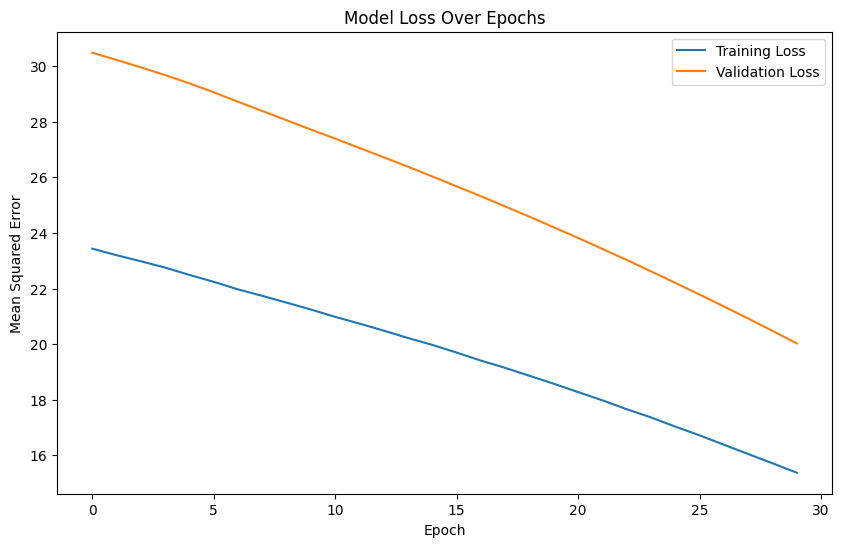

In [ ]:
# Step 7: Visualize results
# Plot training history
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.show()



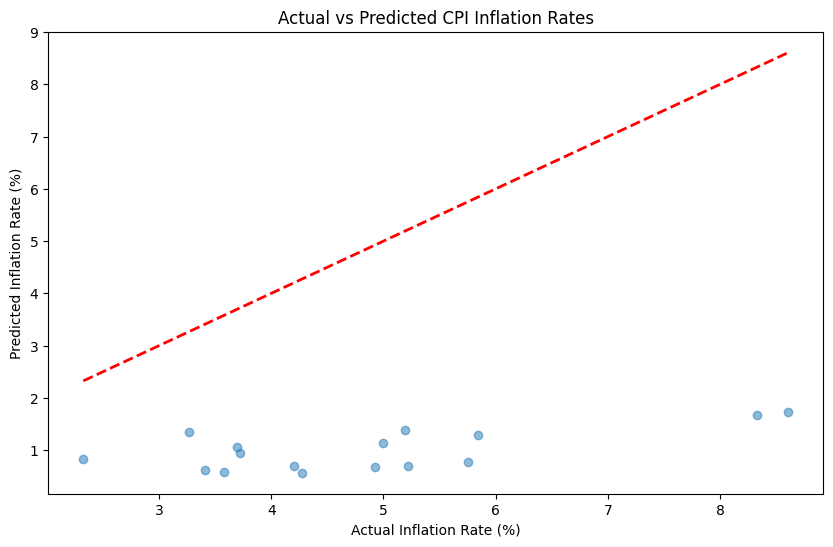

In [ ]:
# Scatter plot of actual vs predicted inflation rates
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Inflation Rate (%)')
plt.ylabel('Predicted Inflation Rate (%)')
plt.title('Actual vs Predicted CPI Inflation Rates')
plt.show()